# Train Model


In [68]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv('df_final_Q1.csv')

features = [
    'prev_1y_league_pts_per_game', 'prev_1y_goal_diff_per_game', 'prev_1y_team_save_pct',
    'prev_1y_player_pts_per_game', 'prev_1y_player_pim_per_game', 'prev_1y_num_coaches',
    'prev_rank', 'prev_playoff', 'league_pts_avg_3y', 'league_pts_momentum', 'league_pts_consistency_3y'
]

#select the season and divide the train and test
target_season = 2009
train = df[df['year'] < target_season].copy()
test = df[df['year'] == target_season].copy()

# fill the missing values with the median
train_medians = train[features].median()
train[features] = train[features].fillna(train_medians)
test[features] = test[features].fillna(train_medians) 

X_train, y_train_reg = train[features], train['target']
X_test, y_test_reg = test[features], test['target']

print(f"Target season: {target_season}")
print(f"Train: {train['year'].min()} a {train['year'].max()} ({X_train.shape[0]} teams)")
print(f"Target: {target_season} ({X_test.shape[0]} teams)")


Target season: 2009
Train: 1983 a 2008 (639 teams)
Target: 2009 (30 teams)


## Select the models and train them

In [69]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

test_previsions = {}
comp_table = []

for name, model in models.items():
    model.fit(X_train, y_train_reg)
    
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    test_previsions[name] = pred_test
    
    #calc error in each model
    temp_df = test[['divID', 'target_rank']].copy()
    temp_df['pts'] = pred_test
    temp_df['rank_pred'] = temp_df.groupby('divID')['pts'].rank(ascending = False, method = 'first').astype(int)
    error_rank = abs(temp_df['target_rank'] - temp_df['rank_pred']).mean()
    
    comp_table.append({
        'Algorithm': name,
        'RMSE Train': round(np.sqrt(mean_squared_error(y_train_reg, pred_train)), 3),
        'RMSE Test': round(np.sqrt(mean_squared_error(y_test_reg, pred_test)), 3),
        'R2 Test': round(r2_score(y_test_reg, pred_test), 3),
        'Average error in ranks': round(error_rank, 2)
    })

df_result_models = pd.DataFrame(comp_table)
print("Results of each model")
display(df_result_models)


Results of each model


,Algorithm,RMSE Train,RMSE Test,R2 Test,Average error in ranks
0,Linear Regression,0.773,0.880,0.199,1.20
1,KNN Regressor,0.705,0.939,0.088,1.20
2,Random Forest,0.319,0.857,0.241,1.13
3,Gradient Boosting,0.536,0.844,0.263,1.13


## Classification

In [70]:
best_model = "Gradient Boosting"
res = test[['tmID', 'confID', 'divID', 'target_rank']].copy()
res['predicted_points'] =  test_previsions[best_model]

# transform the points predicted in a ranking
res['predicted_rank'] = res.groupby('divID')['predicted_points'].rank(ascending = False, method = 'first').astype(int)
res['error_rank'] = abs(res['target_rank'] - res['predicted_rank'])

print(f"Final ranking ({best_model}): {target_season}")

#by division
global_table = res.sort_values(['divID', 'target_rank'])
display(global_table[['tmID', 'confID', 'divID', 'target_rank', 'predicted_points', 'predicted_rank', 'error_rank']])


Final ranking (Gradient Boosting): 2009


,tmID,confID,divID,target_rank,predicted_points,predicted_rank,error_rank
372,NJD,EC,AT,1,0.398280,2,1
519,PIT,EC,AT,2,0.748361,1,1
467,PHI,EC,AT,3,0.294677,3,0
424,NYR,EC,AT,4,0.021639,4,0
398,NYI,EC,AT,5,-1.212282,5,0
154,CHI,WC,CE,1,0.356386,2,1
232,DET,WC,CE,2,2.011664,1,1
346,NAS,WC,CE,3,0.085328,3,0
563,STL,WC,CE,4,-0.315593,4,0
128,CBS,WC,CE,5,-0.368965,5,0


## Feature Importance

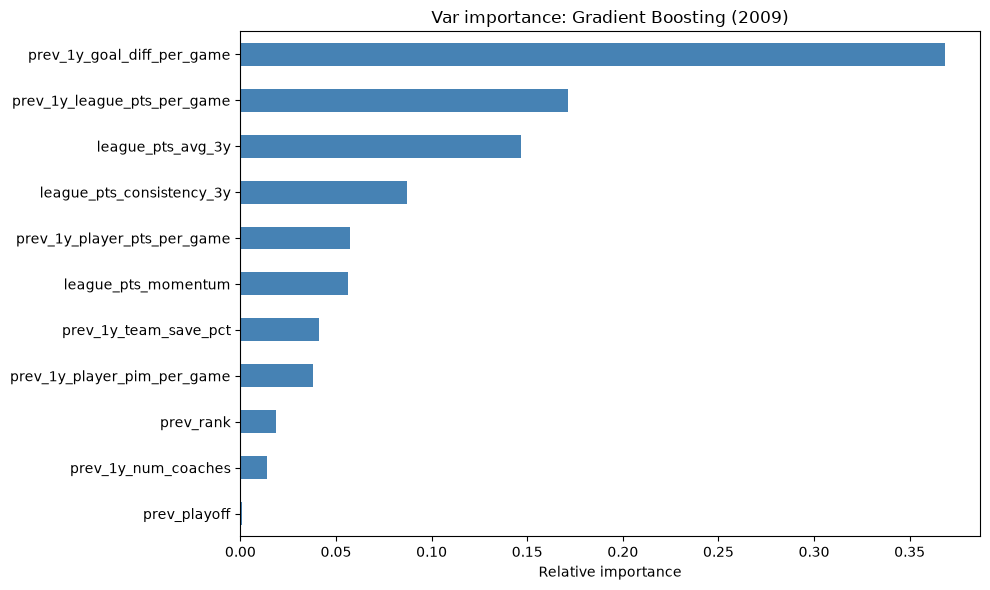

In [71]:
winner_model = models["Gradient Boosting"]
relevant = pd.Series(winner_model.feature_importances_, index = features).sort_values(ascending = True)

plt.figure(figsize = (10, 6))
relevant.plot(kind = 'barh', color = 'steelblue')
plt.title(f'Var importance: {best_model} ({target_season})')
plt.xlabel('Relative importance')
plt.tight_layout()
plt.show()
